<a href="https://colab.research.google.com/github/amulyasundaresan/Midterm-1/blob/main/Notebooks/midterm_combined_notebook_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/amulyasundaresan/Midterm-1/blob/main/Notebooks/Midterm_Combined_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# DS2002 Midterm: Walmart Hurricane Analytics
## Combined notebook: data loading, cleaning pipeline, weather API, first join


### What changed when merging (so nobody is surprised)

| # | What | Why it mattered |
|---|---|---|
| 1 | **SKU map rebuilt from the catalog.** The old map had 9 keys, but 5 of them (`PTOWAL-6`, `PAPER-TOWEL-6`, `POPTART-STRAWBERRY`, `POPTART_STRAWBERRY`, `BATT-AA4`) do not exist in any file, and 3 real variants were missed. It only merged 4 of the 45 SKUs, and **two of the four Pop-Tart SKUs (`PT-12`, `SKU#459812`) were left unmerged.** | Q2 (Pop-Tarts) and Q5 (Monopoly has 3 SKUs) would have been wrong. |
| 2 | Raw `sku` is **kept**; `canonical_sku` / `canonical_product` are added. | Q2 needs a before (fragmented) vs after (consolidated) view. |
| 3 | One shared `CATEGORY_MAP` and one `clean_store_id()` used for every file. | The older notebook left `alcohol`, `electronics`, `snacks` lower-case in the sales table. |
| 4 | `state` mapping fixed (it lower-cased the value, then looked up upper-case keys, so it matched 0 rows). | Silent bug, log said 0 rows. |
| 5 | Timestamps parsed with **explicit formats**, with per-format counts. Missing ones get a flag and a **date recovered from neighbouring transaction ids** (validated below). | `format='mixed'` guesses; 884 rows (3.5%) had no time at all. |
| 6 | The weather variable no longer overwrites the weather function; failure now falls back to the saved sample **loudly**. | The old cell crashed on any API failure. |
| 7 | Missing wind/precipitation are left `NaN`, not filled with 0. | 0 wind is a claim about the weather, not a missing value. |
| 8 | Every cleaning function works on a **copy**, so re-running a cell no longer cleans the data twice. | Hidden source of "it worked yesterday" bugs. |

## 1. Setup

In [113]:
import os, re, time, glob, sqlite3, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
print('pandas', pd.__version__)

pandas 2.2.3


In [114]:
# ---- Decision log: every cleaning decision goes through log() -------------------------------
DECISIONS = []

def log(file_name, step, decision, rows_affected):
    DECISIONS.append({'file': file_name, 'step': step, 'decision': decision,
                      'rows_affected': int(rows_affected)})
    print(f"[{file_name}] {step}: {decision} ({int(rows_affected):,} row(s))")

def show_log():
    return pd.DataFrame(DECISIONS)

## 2. Data loading (untouched)



In [115]:
GITHUB_RAW = 'https://raw.githubusercontent.com/amulyasundaresan/Midterm-1/refs/heads/main/Data'

def get_data(filename):
    for folder in ['data', '../data', '/content', '.'] + glob.glob('/kaggle/input/*'):
        path = os.path.join(folder, filename)
        if os.path.exists(path):
            return path
    os.makedirs('data', exist_ok=True)
    dest = os.path.join('data', filename)
    print(f'{filename} not found locally, downloading from GitHub...')
    urllib.request.urlretrieve(f'{GITHUB_RAW}/{filename}', dest)
    return dest

RAW = {
    'transactions': pd.read_csv(get_data('walmart_transactions.csv')),
    'stores':       pd.read_csv(get_data('store_locations.csv')),
    'products':     pd.read_csv(get_data('product_catalog.csv')),
    'dcs':          pd.read_csv(get_data('distribution_centers.csv')),
}

# The SQLite database (used mostly for Q5). Keep the connection open for your SQL queries.
conn = sqlite3.connect(get_data('inventory_and_sales.db'))
print('tables in the database:', pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)['name'].tolist())
RAW['inventory'] = pd.read_sql('SELECT * FROM inventory_levels', conn)
RAW['daily_sales'] = pd.read_sql('SELECT * FROM daily_sales_summary', conn)

for name, df in RAW.items():
    print(f'{name:13s} {df.shape[0]:>7,} rows x {df.shape[1]} cols')

tables in the database: ['daily_sales_summary', 'inventory_levels']
transactions   25,562 rows x 8 cols
stores             14 rows x 8 cols
products           45 rows x 7 cols
dcs                 5 rows x 8 cols
inventory       4,320 rows x 6 cols
daily_sales     3,600 rows x 5 cols


In [116]:
# Profile of the raw transactions (the function from the kickoff lecture)
def profile(df, name='dataset'):
    print(f'=== {name} ===')
    print(f'{len(df):,} rows x {len(df.columns)} columns\n')
    print(pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isnull().sum(),
        'null_pct': (100 * df.isnull().mean()).round(1),
        'distinct': df.nunique(),
    }))
    print('\nexact duplicate rows:', df.duplicated().sum())

profile(RAW['transactions'], 'walmart_transactions (RAW)')

=== walmart_transactions (RAW) ===
25,562 rows x 8 columns

                 dtype  nulls  null_pct  distinct
transaction_id  object      0       0.0     25532
store_id        object      0       0.0        60
timestamp       object    886       3.5     23952
sku             object      0       0.0        45
product_name    object      0       0.0        63
category        object      0       0.0        37
quantity         int64      0       0.0        11
unit_price      object      0       0.0      3668

exact duplicate rows: 30


## 3. Lookup tables: categories and the SKU map

**Categories.** Raw spellings seen: `EMERGENCY`, `emergency`, `Emergency`, `Emergency Supplies`, `Groceries`, `Games & Entertainment`, `Health & Wellness`... One map, used for every file.


In [117]:
CATEGORY_MAP = {
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'emergency': 'Emergency Supplies', 'emergency supplies': 'Emergency Supplies',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'baby': 'Baby Products', 'baby products': 'Baby Products',
    'alcohol': 'Alcohol', 'alcohol drinks': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'game & entertainment': 'Game & Entertainment', 'games & entertainment': 'Game & Entertainment',
    'game': 'Game & Entertainment', 'entertainment': 'Game & Entertainment',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'electronics': 'Electronics',
    'snacks': 'Snacks',
}
CANONICAL_CATEGORIES = set(CATEGORY_MAP.values())

def clean_category(s):
    key = s.astype('string').str.strip().str.lower()
    return key.map(CATEGORY_MAP).fillna(key.str.title())

In [118]:
# canonical_sku -> (display name, [every SKU variant seen in the catalog / transactions / database])
SKU_FAMILIES = {
    'POPTART-STRAW': ('Pop-Tarts Strawberry',    ['PT-12', 'SKU#459812', 'POPTART-STRAW', 'PT_STRAWBERRY']),
    'WTR_24PK':      ('Bottled Water 24-Pack',   ['WTR-24', 'WATER24PK', 'WTR_24PK']),
    'BATT_AA_4PK':   ('AA Batteries 4-Pack',     ['BATT-100', 'BAT-AA4', 'BATT_AA_4PK']),
    'FLASH-01':      ('LED Flashlight',          ['FLASH-01', 'LED-FLASH']),
    'BEER-24':       ('Light Beer 24-Pack',      ['BEER-24', 'LTBEER24']),
    'MONOPOLY-01':   ('Monopoly Board Game',     ['BG-MONO', 'MONOPOLY-01', 'GAME-MONO']),
    'CARDS-01':      ('Playing Cards',           ['CARDS-01', 'PLAYCARD-STD']),
    'STREAM-01':     ('Roku Streaming Stick',    ['STREAM-01', 'ROKU-STD']),
    'CNSOUP-01':     ('Canned Soup',             ['SOUP-CAN', 'CNSOUP-01']),
    'BREAD-WH':      ('White Bread',             ['BREAD-WH', 'WHITEBREAD']),
    'PB-16':         ('Peanut Butter 16oz',      ['PB-16', 'PNUTBTR-16']),
    'CNDL-EM':       ('Emergency Candles',       ['CNDL-EM', 'CANDLE-EMRG']),
    'FAID-01':       ('First-Aid Kit',           ['FAID-01', 'FIRSTAID-KIT']),
    'CHRG-PORT':     ('Portable Charger',        ['CHRG-PORT', 'PORTCHARGER']),
    'CHIPS-VP':      ('Chips Variety Pack',      ['CHIPS-VP', 'CHIPVARIETY']),
    'PAPERTOWEL6':   ('Paper Towels 6-Pack',     ['PTOWEL-6', 'PAPERTOWEL6']),
    'TOILETPAPER12': ('Toilet Paper 12-Roll',    ['TP-12', 'TOILETPAPER12']),
    'DIAPERS-3':     ('Baby Diapers Size 3',     ['DIAP-S3', 'DIAPERS-3']),
    'BABYFORMULA':   ('Infant Formula',          ['BFORM-01', 'BABYFORMULA']),
    'TARP-HD':       ('Heavy Duty Tarp',         ['TARP-HD', 'HDTARP-01']),
}
SKU_TO_CANON = {v: canon for canon, (_, variants) in SKU_FAMILIES.items() for v in variants}
CANON_NAME   = {canon: name for canon, (name, _) in SKU_FAMILIES.items()}

# SKUs that appear ONLY in the inventory database and in no catalog. We do not guess what they are.
ORPHAN_SKUS = {'UNKNOWN-99', 'LEGACY-PT', 'OLD-BATT-50', 'MISC-001'}

# Safety net: every SKU in every file must be either mapped or a known orphan.
all_skus = (set(RAW['transactions']['sku'].str.strip()) | set(RAW['products']['sku'].str.strip())
            | set(RAW['inventory']['sku'].str.strip().str.upper()))
unmapped = all_skus - set(SKU_TO_CANON) - ORPHAN_SKUS
assert not unmapped, f'SKUs with no mapping, add them to SKU_FAMILIES: {unmapped}'
print(f'{len(SKU_TO_CANON)} SKU variants map to {len(SKU_FAMILIES)} canonical products; {len(ORPHAN_SKUS)} orphan SKUs flagged')

45 SKU variants map to 20 canonical products; 4 orphan SKUs flagged


In [119]:
# Small cleaning helpers shared by every file
def strip_text(df):
    # Strip leading/trailing spaces in every text column. Works on pandas 2 (object) and pandas 3 (str).
    # Returns the cleaned frame and how many rows had at least one value changed.
    df = df.copy()
    changed = pd.Series(False, index=df.index)
    for c in df.columns:
        if df[c].dtype == object or pd.api.types.is_string_dtype(df[c]):
            old = df[c].astype('string')
            new = old.str.strip()
            changed |= (old != new).fillna(False)
            df[c] = new
    return df, int(changed.sum())

def clean_store_id(s):
    # FL710, fl_710, ' FL-710', 'FL 710' -> 'FL-710'
    s = s.astype('string').str.strip().str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)
    return s.str.replace(r'^FL(\d+)$', r'FL-\1', regex=True)

def to_money(s):
    # '$9.64', ' 19.32 ', '3.15' -> float
    return pd.to_numeric(s.astype('string').str.replace(r'[$,\s]', '', regex=True), errors='coerce')

# Timestamps arrive in 5 different layouts. Explicit formats, tried in order, so nothing is guessed.
# (For the slash and dash layouts the first number is always 09 and the second runs 1-30, so they are month-first.)
TS_FORMATS = [
    ('%Y-%m-%d %H:%M:%S', '2024-09-02 20:30:20'),
    ('%Y-%m-%dT%H:%M:%S', '2024-09-13T09:48:13'),
    ('%m/%d/%Y %H:%M',    '09/15/2024 09:26'),
    ('%d-%b-%Y %H:%M',    '15-Sep-2024 09:26'),
    ('%m-%d-%Y %H:%M:%S', '09-12-2024 18:24:47'),
]
MISSING_TOKENS = ['NULL', 'N/A', 'NA', 'nan', 'NaN', 'None', '']

def parse_timestamps(s, file_name='walmart'):
    s = s.astype('string').str.strip()
    s = s.mask(s.isin(MISSING_TOKENS))
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    for fmt, example in TS_FORMATS:
        todo = out.isna() & s.notna()
        parsed = pd.to_datetime(s[todo], format=fmt, errors='coerce')
        out.loc[todo] = parsed
        log(file_name, 'Timestamp', f'parsed layout {fmt}  e.g. {example}', parsed.notna().sum())
    return out

## 4. Cleaning functions

One function per file. Each takes the raw frame and returns a clean **copy**.

**negative quantities?** The brief calls them data entry errors (130 rows). `NEG_QTY_POLICY` below chooses what to do:
`'abs'` flips the sign and keeps the row (assumes a typo in the sign), `'drop'` removes them, `'keep'` leaves them negative so they subtract from totals. A comparison of the three is printed further down. pick one?

In [120]:
NEG_QTY_POLICY = 'abs'      # 'abs' | 'drop' | 'keep'   <- TEAM DECISION, justify it in the log

def add_best_date(df):
    # Missing timestamps: transaction ids are nearly time-ordered (rank correlation ~0.995). If the nearest known
    # transaction before AND after both fall on the same day, the missing one is on that day too.
    # We only recover the DATE, never the hour. Rows where the neighbours disagree stay NaT.
    tmp = df.sort_values('txn_num')
    known = tmp['timestamp'].dt.normalize()
    prev, nxt = known.ffill(), known.bfill()
    recoverable = known.isna() & (prev == nxt)
    best = known.copy()
    best[recoverable] = prev[recoverable]
    df['date_best'] = best                       # aligned back on the index
    df['date_imputed'] = recoverable.astype(int)
    return df

def clean_walmart_transactions(df_raw, neg_policy=None):
    neg_policy = neg_policy or NEG_QTY_POLICY
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('walmart', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)

    n = len(df)
    df = df.drop_duplicates().copy()
    log('walmart', 'Duplicates', 'dropped exact duplicate rows', n - len(df))
    assert df['transaction_id'].is_unique, 'transaction_id should be unique after de-duplication'

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('walmart', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    has_dollar = df['unit_price'].astype('string').str.contains(r'\$', na=False).sum()
    df['unit_price'] = to_money(df['unit_price'])
    log('walmart', 'Price', "removed '$' and spaces, converted unit_price to float", has_dollar)
    log('walmart', 'Price', 'unit_price values that could not be parsed (left NaN)', df['unit_price'].isna().sum())

    df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')
    df['is_neg_qty'] = (df['quantity'] < 0).astype(int)
    n_neg = int(df['is_neg_qty'].sum())
    if neg_policy == 'abs':
        df['quantity_clean'] = df['quantity'].abs()
        log('walmart', 'Negative qty', "policy 'abs': sign flipped, rows kept (assumed sign typo)", n_neg)
    elif neg_policy == 'drop':
        df = df[df['quantity'] >= 0].copy()
        df['quantity_clean'] = df['quantity']
        log('walmart', 'Negative qty', "policy 'drop': rows removed", n_neg)
    else:
        df['quantity_clean'] = df['quantity']
        log('walmart', 'Negative qty', "policy 'keep': left negative, flagged in is_neg_qty", n_neg)

    before = df['category'].copy()
    df['category'] = clean_category(df['category'])
    log('walmart', 'Category', 'mapped spelling variants to 10 canonical categories', (before != df['category']).sum())
    assert set(df['category'].dropna()) <= CANONICAL_CATEGORIES, 'unknown category slipped through'

    # SKU: keep the raw sku, add canonical columns
    df['canonical_sku'] = df['sku'].map(SKU_TO_CANON)
    df['canonical_product'] = df['canonical_sku'].map(CANON_NAME)
    changed = (df['sku'] != df['canonical_sku']).sum()
    log('walmart', 'SKU', 'added canonical_sku / canonical_product (raw sku kept)', changed)
    assert df['canonical_sku'].notna().all(), 'a transaction SKU has no mapping'

    # Timestamps
    df['txn_num'] = df['transaction_id'].str.extract(r'(\d+)')[0].astype(int)
    df['timestamp'] = parse_timestamps(df['timestamp'])
    df['timestamp_missing'] = df['timestamp'].isna().astype(int)
    log('walmart', 'Timestamp', 'no timestamp at all (kept as NaT, flagged timestamp_missing)', df['timestamp_missing'].sum())
    df['date'] = df['timestamp'].dt.normalize()        # strict: only from a real timestamp
    df['hour'] = df['timestamp'].dt.hour
    df = add_best_date(df)
    log('walmart', 'Timestamp', 'recovered the DATE from neighbouring transaction ids (date_best, flagged date_imputed)', df['date_imputed'].sum())
    log('walmart', 'Timestamp', 'still no date after recovery (excluded from daily charts)', df['date_best'].isna().sum())

    df['revenue'] = df['quantity_clean'] * df['unit_price']
    return df.sort_values('txn_num').reset_index(drop=True)

In [121]:
def clean_product_catalog(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('products', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)

    n = len(df); df = df.drop_duplicates().copy()
    log('products', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    before = df['category'].copy()
    df['category'] = clean_category(df['category'])
    log('products', 'Category', 'mapped to canonical categories', (before != df['category']).sum())

    df['canonical_sku'] = df['sku'].map(SKU_TO_CANON)
    df['canonical_product'] = df['canonical_sku'].map(CANON_NAME)
    log('products', 'SKU', 'added canonical_sku / canonical_product', df['canonical_sku'].notna().sum())

    df['unit_cost'] = pd.to_numeric(df['unit_cost'], errors='coerce')
    df['unit_cost_imputed'] = df['unit_cost'].isna().astype(int)
    # a missing cost is best estimated from the SAME product under another SKU; fall back to category median
    fam_med = df.groupby('canonical_sku')['unit_cost'].transform('median')
    cat_med = df.groupby('category')['unit_cost'].transform('median')
    df['unit_cost'] = df['unit_cost'].fillna(fam_med).fillna(cat_med)
    log('products', 'Missing', 'unit_cost filled with the median of the same canonical product (else category)', df['unit_cost_imputed'].sum())

    n_sub = df['subcategory'].isna().sum()
    df['subcategory'] = df['subcategory'].fillna('Unknown')
    log('products', 'Missing', "subcategory filled with 'Unknown'", n_sub)

    old_ps = df['package_size'].astype('string')
    df['package_size'] = old_ps.str.lower().str.replace('-', ' ', regex=False)
    log('products', 'Format', 'package_size lower-cased, hyphens removed (this column is noisy: do not use it to match products)', (old_ps != df['package_size']).sum())
    return df

def clean_store_locations(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('stores', 'Whitespace', 'stripped leading/trailing spaces (e.g. region " Panhandle")', n_ws)

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('stores', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    n = len(df); df = df.drop_duplicates(subset=['store_id'], keep='first').copy()
    log('stores', 'Duplicates', 'dropped repeat store rows (FL239 = FL-239, FL_287 = FL-287)', n - len(df))

    st = df['state'].astype('string').str.upper().str.replace('.', '', regex=False)
    new_state = st.replace({'FLORIDA': 'FL', 'FLA': 'FL'})
    log('stores', 'State', "FL / Florida / Fla. -> 'FL'", (df['state'] != new_state).sum())
    df['state'] = new_state

    df['latitude'] = pd.to_numeric(df['latitude'], errors='coerce')
    df['longitude'] = pd.to_numeric(df['longitude'], errors='coerce')
    n_missing = (df['latitude'].isna() | df['longitude'].isna()).sum()
    # EXTERNAL FACT, not derived from the data: Tallahassee city-centre coordinates
    CITY_COORDS = {'Tallahassee': (30.4383, -84.2807)}
    for city, (lat, lon) in CITY_COORDS.items():
        m = df['city'] == city
        df.loc[m & df['latitude'].isna(), 'latitude'] = lat
        df.loc[m & df['longitude'].isna(), 'longitude'] = lon
    log('stores', 'Missing', 'filled missing lat/lon from known Tallahassee city-centre coordinates (external reference)', n_missing)
    assert df[['latitude', 'longitude']].notna().all().all(), 'a store still has no coordinates'
    return df.reset_index(drop=True)

def clean_distribution_center(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('dcs', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)
    n = len(df); df = df.drop_duplicates().copy()
    log('dcs', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    tilde = df['surge_capacity'].astype('string').str.contains('~', na=False).sum()
    df['surge_capacity'] = df['surge_capacity'].astype('string').str.replace('~', '', regex=False)
    log('dcs', 'Format', "removed '~' from surge_capacity (it was an estimate)", tilde)

    for c in ['avg_daily_shipments', 'surge_capacity', 'distance_to_orlando_mi', 'cost_per_shipment']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    log('dcs', 'Numeric', 'converted numeric columns', len(df))

    df['cost_imputed'] = df['cost_per_shipment'].isna().astype(int)
    median_cost = df['cost_per_shipment'].median()
    if pd.notna(median_cost):
        df['cost_per_shipment'] = (
            df['cost_per_shipment'].fillna(median_cost)
    )
    log('dcs', 'Missing', 'cost_per_shipment filled with median (flagged cost_imputed; 5 rows only, treat with caution)', df['cost_imputed'].sum())
    return df

In [122]:
def clean_inventory(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('inventory', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)
    n = len(df); df = df.drop_duplicates().copy()
    log('inventory', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('inventory', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d', errors='coerce')
    log('inventory', 'Date', 'parsed (unparseable would be NaT)', df['date'].isna().sum())

    for c in ['units_on_hand', 'units_on_order', 'reorder_point']:
        df[c] = pd.to_numeric(df[c], errors='coerce')

    df['sku'] = df['sku'].str.upper()
    df['canonical_sku'] = df['sku'].map(SKU_TO_CANON)
    df['is_orphan_sku'] = df['sku'].isin(ORPHAN_SKUS).astype(int)
    df.loc[df['is_orphan_sku'] == 1, 'canonical_sku'] = 'UNRESOLVED'
    df['canonical_product'] = df['canonical_sku'].map(CANON_NAME).fillna('UNRESOLVED')
    log('inventory', 'SKU', 'added canonical_sku (raw kept)', df['canonical_sku'].ne(df['sku']).sum())
    log('inventory', 'SKU', 'orphan SKUs (UNKNOWN-99, LEGACY-PT, OLD-BATT-50, MISC-001) flagged, NOT merged: not in any catalog', df['is_orphan_sku'].sum())
    assert df['canonical_sku'].notna().all()

    df['on_order_missing'] = df['units_on_order'].isna().astype(int)
    df['units_on_order'] = df['units_on_order'].fillna(0)
    log('inventory', 'Missing', 'units_on_order NaN -> 0 (ASSUMPTION: nothing on order; flagged on_order_missing)', df['on_order_missing'].sum())
    return df

def clean_daily_sales(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    df, n_ws = strip_text(df)
    log('daily_sales', 'Whitespace', 'stripped leading/trailing spaces in text columns', n_ws)
    n = len(df); df = df.drop_duplicates().copy()
    log('daily_sales', 'Duplicates', 'dropped exact duplicate rows', n - len(df))

    before = df['store_id'].copy()
    df['store_id'] = clean_store_id(df['store_id'])
    log('daily_sales', 'Store ID', "standardized to 'FL-###'", (before != df['store_id']).sum())

    # two date layouts live in this table: 2024-09-01 and 20240901
    s = df['date'].astype('string')
    d_iso = pd.to_datetime(s, format='%Y-%m-%d', errors='coerce')
    d_compact = pd.to_datetime(s, format='%Y%m%d', errors='coerce')
    df['date'] = d_iso.fillna(d_compact)
    log('daily_sales', 'Date', 'parsed YYYY-MM-DD and compact YYYYMMDD layouts', d_compact.notna().sum())
    log('daily_sales', 'Date', 'dates that could not be parsed', df['date'].isna().sum())

    before = df['category'].copy()
    df['category'] = clean_category(df['category'])
    log('daily_sales', 'Category', 'mapped to canonical categories', (before != df['category']).sum())

    df['total_units'] = pd.to_numeric(df['total_units'], errors='coerce')
    df['total_revenue'] = pd.to_numeric(df['total_revenue'], errors='coerce')
    frac = (df['total_units'] % 1 != 0).sum()
    df['units_fractional'] = (df['total_units'] % 1 != 0).astype(int)
    log('daily_sales', 'Check', 'total_units has non-whole values like 71.5 (units cannot be fractional): flagged, NOT changed. Look into this for Q5', frac)
    return df

## 5. Run the pipeline

In [123]:
DECISIONS.clear()          # so re-running this cell never double-logs

transactions = clean_walmart_transactions(RAW['transactions'])
products     = clean_product_catalog(RAW['products'])
stores       = clean_store_locations(RAW['stores'])
dcs          = clean_distribution_center(RAW['dcs'])
inventory    = clean_inventory(RAW['inventory'])
daily_sales  = clean_daily_sales(RAW['daily_sales'])

[walmart] Whitespace: stripped leading/trailing spaces in text columns (2,331 row(s))
[walmart] Duplicates: dropped exact duplicate rows (30 row(s))
[walmart] Store ID: standardized to 'FL-###' (3,607 row(s))
[walmart] Price: removed '$' and spaces, converted unit_price to float (3,026 row(s))
[walmart] Price: unit_price values that could not be parsed (left NaN) (0 row(s))
[walmart] Negative qty: policy 'abs': sign flipped, rows kept (assumed sign typo) (130 row(s))
[walmart] Category: mapped spelling variants to 10 canonical categories (19,358 row(s))
[walmart] SKU: added canonical_sku / canonical_product (raw sku kept) (13,988 row(s))
[walmart] Timestamp: parsed layout %Y-%m-%d %H:%M:%S  e.g. 2024-09-02 20:30:20 (12,169 row(s))
[walmart] Timestamp: parsed layout %Y-%m-%dT%H:%M:%S  e.g. 2024-09-13T09:48:13 (2,504 row(s))
[walmart] Timestamp: parsed layout %m/%d/%Y %H:%M  e.g. 09/15/2024 09:26 (5,027 row(s))
[walmart] Timestamp: parsed layout %d-%b-%Y %H:%M  e.g. 15-Sep-2024 09:26 (2,

In [124]:
# Rows before and after, one line per file (the checkpoint asks for this)
CLEAN = {'transactions': transactions, 'stores': stores, 'products': products,
         'dcs': dcs, 'inventory': inventory, 'daily_sales': daily_sales}
rows = pd.DataFrame({'raw_rows': {k: len(RAW[k]) for k in CLEAN},
                     'clean_rows': {k: len(v) for k, v in CLEAN.items()}})
rows['rows_removed'] = rows['raw_rows'] - rows['clean_rows']
rows

,raw_rows,clean_rows,rows_removed
transactions,25562,25532,30
stores,14,12,2
products,45,45,0
dcs,5,5,0
inventory,4320,4320,0
daily_sales,3600,3600,0


## 6. Two decisions you should be able to defend

### 6a. Negative quantities: what does each policy do to the totals?

In [125]:
raw_tx = RAW['transactions'].drop_duplicates().copy()
q = pd.to_numeric(raw_tx['quantity'], errors='coerce')
compare = pd.DataFrame({
    'policy': ["keep (negative stays negative)", "abs (flip sign)", "drop (remove rows)"],
    'rows':   [len(q), len(q), int((q >= 0).sum())],
    'total_units': [int(q.sum()), int(q.abs().sum()), int(q[q >= 0].sum())],
})
compare['difference_vs_abs'] = compare['total_units'] - int(q.abs().sum())
print(f'{int((q < 0).sum())} rows have a negative quantity; current policy = {NEG_QTY_POLICY!r}')
compare

130 rows have a negative quantity; current policy = 'abs'


,policy,rows,total_units,difference_vs_abs
0,keep (negative stays negative),25532,49343,-482
1,abs (flip sign),25532,49825,0
2,drop (remove rows),25402,49584,-241


### 6b. Recovering dates for rows with no timestamp: does it actually work?

Test: hide 10% of the timestamps we *do* know, recover them with the same neighbour rule, and compare with the truth. If the accuracy is high we can trust the rule on the rows that are really missing.

In [126]:
t = transactions.sort_values('txn_num')[['txn_num', 'timestamp']].reset_index(drop=True)
known = t['timestamp'].notna()
rng = np.random.default_rng(42)
hide = known & (rng.random(len(t)) < 0.10)
hidden_ts = t['timestamp'].where(~hide)
d = hidden_ts.dt.normalize()
prev, nxt = d.ffill(), d.bfill()
recoverable = hide & (prev == nxt)
truth = t['timestamp'].dt.normalize()
print(f'hid {hide.sum():,} known timestamps')
print(f'  neighbours agreed on a date for {recoverable.sum() / hide.sum():.1%} of them')
print(f'  of those, the recovered date was correct {(prev[recoverable] == truth[recoverable]).mean():.1%} of the time')
print(f'rows really missing a timestamp: {transactions["timestamp_missing"].sum():,}  '
      f'-> dates recovered for {transactions["date_imputed"].sum():,}, '
      f'still unknown for {transactions["date_best"].isna().sum():,}')

hid 2,436 known timestamps
  neighbours agreed on a date for 99.5% of them
  of those, the recovered date was correct 100.0% of the time
rows really missing a timestamp: 884  -> dates recovered for 883, still unknown for 1


## 7. Final checks (shape, nulls, duplicates, dtypes, and do the files agree with each other)

In [127]:
def final_check(df, name, key_cols=None):
    print(f'--- {name}: {df.shape[0]:,} rows x {df.shape[1]} cols ---')
    nulls = df.isna().sum()
    print('columns with nulls:', nulls[nulls > 0].to_dict() or 'none')
    print('exact duplicate rows:', df.duplicated().sum())
    if key_cols:
        print('duplicate keys:', df.duplicated(subset=key_cols).sum())
    print()

final_check(transactions, 'transactions', ['transaction_id'])
final_check(stores, 'stores', ['store_id'])
final_check(products, 'products', ['sku'])
final_check(dcs, 'distribution centers', ['dc_id'])
final_check(inventory, 'inventory', ['date', 'store_id', 'sku'])
final_check(daily_sales, 'daily_sales', ['date', 'store_id', 'category'])

--- transactions: 25,532 rows x 19 cols ---
columns with nulls: {'timestamp': 884, 'date': 884, 'hour': 884, 'date_best': 1}
exact duplicate rows: 0
duplicate keys: 0

--- stores: 12 rows x 8 cols ---
columns with nulls: none
exact duplicate rows: 0
duplicate keys: 0

--- products: 45 rows x 10 cols ---
columns with nulls: none
exact duplicate rows: 0
duplicate keys: 0

--- distribution centers: 5 rows x 9 cols ---
columns with nulls: none
exact duplicate rows: 0
duplicate keys: 0

--- inventory: 4,320 rows x 10 cols ---
columns with nulls: none
exact duplicate rows: 0
duplicate keys: 0

--- daily_sales: 3,600 rows x 6 cols ---
columns with nulls: none
exact duplicate rows: 0
duplicate keys: 0



In [128]:
# Cross-file integrity: if these fail, a join later will silently drop or duplicate rows.
store_ids = set(stores['store_id'])
checks = {
    'transaction store_ids all in stores':        set(transactions['store_id']) <= store_ids,
    'inventory store_ids all in stores':          set(inventory['store_id']) <= store_ids,
    'daily_sales store_ids all in stores':        set(daily_sales['store_id']) <= store_ids,
    'every transaction SKU is in the catalog':    set(transactions['sku']) <= set(products['sku']),
    'every store has coordinates':                bool(stores[['latitude', 'longitude']].notna().all().all()),
    'transaction dates fall in Sept 2024':        bool(transactions['date_best'].dropna().between('2024-09-01', '2024-09-30').all()),
    'daily_sales dates fall in Sept 2024':        bool(daily_sales['date'].between('2024-09-01', '2024-09-30').all()),
}
for label, ok in checks.items():
    print('PASS' if ok else 'FAIL', '-', label)

# Does the category on each transaction agree with the catalog's category for that SKU?
cat_lookup = products.set_index('sku')['category']
mismatch = (transactions['category'] != transactions['sku'].map(cat_lookup)).sum()
print(f'\ntransactions whose category disagrees with the catalog category for their SKU: {mismatch:,}')

PASS - transaction store_ids all in stores
PASS - inventory store_ids all in stores
PASS - daily_sales store_ids all in stores
PASS - every transaction SKU is in the catalog
PASS - every store has coordinates
PASS - transaction dates fall in Sept 2024
PASS - daily_sales dates fall in Sept 2024

transactions whose category disagrees with the catalog category for their SKU: 0


## 8. SKU consolidation progress (checkpoint item 3)

This is the table Q2 is built on. The raw `sku` column is the **fragmented** view; `canonical_sku` is the **consolidated** view.

In [129]:
sku_map_table = (products[['sku', 'canonical_sku', 'canonical_product', 'category']]
                 .sort_values(['canonical_product', 'sku']).reset_index(drop=True))
group_sizes = sku_map_table.groupby('canonical_product')['sku'].nunique().sort_values(ascending=False)

print(f"distinct SKUs in the raw transactions : {RAW['transactions']['sku'].nunique()}")
print(f"canonical products after consolidation : {transactions['canonical_sku'].nunique()}")
print(f"largest consolidated group             : {group_sizes.index[0]} ({group_sizes.iloc[0]} SKUs)")
print('groups with 3+ SKUs                    :', group_sizes[group_sizes >= 3].to_dict())
print()
print('Pop-Tarts mapping:')
sku_map_table[sku_map_table['canonical_product'] == 'Pop-Tarts Strawberry']

distinct SKUs in the raw transactions : 45
canonical products after consolidation : 20
largest consolidated group             : Pop-Tarts Strawberry (4 SKUs)
groups with 3+ SKUs                    : {'Pop-Tarts Strawberry': 4, 'AA Batteries 4-Pack': 3, 'Monopoly Board Game': 3, 'Bottled Water 24-Pack': 3}

Pop-Tarts mapping:


,sku,canonical_sku,canonical_product,category
33,POPTART-STRAW,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
34,PT-12,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
35,PT_STRAWBERRY,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast
36,SKU#459812,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast


In [130]:
# Fragmented vs consolidated, for Pop-Tarts, in units sold over the whole month
pt = transactions[transactions['canonical_sku'] == 'POPTART-STRAW']
fragmented = pt.groupby('sku')['quantity_clean'].sum().sort_values(ascending=False)
print('Fragmented view (one number per SKU):')
print(fragmented.to_string())
print(f"\nConsolidated view: {int(fragmented.sum()):,} units, across {fragmented.size} SKUs")
print(f"Largest single SKU alone shows only {fragmented.iloc[0] / fragmented.sum():.0%} of true Pop-Tarts volume")

Fragmented view (one number per SKU):
sku
PT-12            1385
POPTART-STRAW    1306
PT_STRAWBERRY    1270
SKU#459812       1257

Consolidated view: 5,218 units, across 4 SKUs
Largest single SKU alone shows only 27% of true Pop-Tarts volume


## 9. Weather API

**Source:** Open-Meteo Historical Weather API, `https://archive-api.open-meteo.com/v1/archive` (free, no key).

**Timezones.** We ask for `timezone='America/New_York'`, so the daily rows are already on the **same local clock as the sales data**. The brief says the sales data is in EST (in September Florida is really on EDT, daylight time; pick one convention and state it). If you pull *hourly* data in UTC you must convert it before joining, which is shown in the optional hourly cell below.

**Failure behaviour.** The call retries on timeouts and on 429/5xx. If it still fails the notebook prints a loud warning and uses a saved copy of the same data; the `source` column says which one you got. Do not submit a notebook whose `source` says `fallback sample` without telling us why.

In [131]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def _get_json(url, params, tries=3):
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(url, params=params, timeout=15)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                 # any other bad status fails loudly
        return r.json()

def fetch_weather(start, end, lat=28.5383, lon=-81.3792, tries=3):
    # Daily weather for one point. Defaults to the Orlando store (FL-239).
    params = {'latitude': lat, 'longitude': lon, 'start_date': start, 'end_date': end,
              'daily': 'precipitation_sum,windspeed_10m_max', 'timezone': 'America/New_York'}
    frame = pd.DataFrame(_get_json(BASE, params, tries)['daily']).rename(columns={'time': 'date'})
    frame['date'] = pd.to_datetime(frame['date'])
    frame['source'] = 'open-meteo'
    return frame

# Saved copy of the same Open-Meteo data (Orlando, Sept 1-30 2024) from the lab, for when the API is down
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

def clean_weather(df_raw):
    df = df_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    n = len(df); df = df.drop_duplicates(subset=['date']).copy()
    log('weather', 'Duplicates', 'dropped repeated dates', n - len(df))
    df['date'] = pd.to_datetime(df['date'], errors='coerce')
    for c in [c for c in df.columns if c not in ('date', 'source')]:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    missing = int(df.drop(columns=['date', 'source']).isna().any(axis=1).sum())
    log('weather', 'Missing', 'rows with a missing weather value, LEFT as NaN (0 wind would be a false claim)', missing)
    return df.sort_values('date').reset_index(drop=True)

In [132]:
try:
    weather_raw = fetch_weather('2024-09-01', '2024-09-30')
    print('Live API call succeeded.')
except requests.RequestException as err:
    print('!' * 70)
    print('API CALL FAILED:', err)
    print('Using the saved fallback sample. Fix this before you submit.')
    print('!' * 70)
    weather_raw = FALLBACK.copy()

weather = clean_weather(weather_raw)
print('source:', weather['source'].iloc[0], '| rows:', len(weather))

if weather['source'].iloc[0] == 'open-meteo':
    d_rain = (weather['precipitation_sum'] - FALLBACK['precipitation_sum']).abs().max()
    d_wind = (weather['windspeed_10m_max'] - FALLBACK['windspeed_10m_max']).abs().max()
    print(f'largest difference from the saved copy: rain {d_rain:.2f} mm, wind {d_wind:.2f} km/h '
          '(if these are not ~0, find out why: units, grid cell, or a data revision)')
weather.head()

Live API call succeeded.
[weather] Duplicates: dropped repeated dates (0 row(s))
[weather] Missing: rows with a missing weather value, LEFT as NaN (0 wind would be a false claim) (0 row(s))
source: open-meteo | rows: 30
largest difference from the saved copy: rain 35.90 mm, wind 6.00 km/h (if these are not ~0, find out why: units, grid cell, or a data revision)


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,6.4,18.7,open-meteo
1,2024-09-02,22.0,12.7,open-meteo
2,2024-09-03,32.7,20.6,open-meteo
3,2024-09-04,21.2,12.6,open-meteo
4,2024-09-05,20.8,15.2,open-meteo


### 9b. NEXT STEP (starter code): hourly weather per store, with pressure, converted from UTC

Q3 asks about **barometric pressure** and a **lag**, and Q4 compares **stores**. The daily Orlando-only pull above has neither pressure nor store detail. This starter pulls hourly wind, rain and sea-level pressure for **each of the 12 store locations** in UTC, then converts to Eastern time. It is wrapped so a failure will not stop "Run All". It has not been verified against the live API from the environment where this notebook was assembled, so check it, and read the Open-Meteo docs for the variable names.

In [133]:
def fetch_weather_hourly(lat, lon, start, end, tries=3):
    params = {'latitude': lat, 'longitude': lon, 'start_date': start, 'end_date': end,
              'hourly': 'precipitation,wind_speed_10m,pressure_msl', 'timezone': 'UTC'}
    h = pd.DataFrame(_get_json(BASE, params, tries)['hourly']).rename(columns={'time': 'time_utc'})
    h['time_utc'] = pd.to_datetime(h['time_utc']).dt.tz_localize('UTC')
    h['time_et'] = h['time_utc'].dt.tz_convert('America/New_York')       # <- the timezone alignment step
    h['date'] = h['time_et'].dt.tz_localize(None).dt.normalize()         # local calendar day, to join to sales
    h['source'] = 'open-meteo hourly'
    return h

weather_hourly = None
try:
    parts = []
    for _, s in stores.iterrows():
        # pad the UTC request by a day on each side: UTC midnight on Sept 1 is 8 pm on Aug 31 in Florida
        h = fetch_weather_hourly(s['latitude'], s['longitude'], '2024-08-31', '2024-10-01')
        h['store_id'] = s['store_id']
        parts.append(h)
        time.sleep(0.3)                                                   # be polite to a free API
    weather_hourly = pd.concat(parts, ignore_index=True)
    weather_hourly = weather_hourly[weather_hourly['date'].between('2024-09-01', '2024-09-30')].reset_index(drop=True)  # keep local Sept days only
    print(f'hourly weather: {len(weather_hourly):,} rows for {weather_hourly["store_id"].nunique()} stores')
    display(weather_hourly.head(3))
except requests.RequestException as err:
    print('Hourly weather not available right now:', err)

hourly weather: 8,640 rows for 12 stores


,time_utc,precipitation,wind_speed_10m,pressure_msl,time_et,date,source,store_id
0,2024-09-01 04:00:00+00:00,0.0,7.9,1015.2,2024-09-01 00:00:00-04:00,2024-09-01,open-meteo hourly,FL-239
1,2024-09-01 05:00:00+00:00,0.0,5.5,1015.0,2024-09-01 01:00:00-04:00,2024-09-01,open-meteo hourly,FL-239
2,2024-09-01 06:00:00+00:00,0.0,5.8,1014.5,2024-09-01 02:00:00-04:00,2024-09-01,open-meteo hourly,FL-239


## 10. Joining weather to sales (with a row-count check)

A join that silently drops or duplicates rows is the most common way to get a wrong answer that looks right. `checked_merge` refuses to continue if the row count changes and tells you how many rows found no weather.

In [134]:
def checked_merge(left, right, on, name):
    n = len(left)
    out = left.merge(right, on=on, how='left', validate='many_to_one', indicator=True)
    assert len(out) == n, f'{name}: row count changed {n} -> {len(out)}'
    no_match = int((out['_merge'] != 'both').sum())
    print(f'{name}: {n:,} rows in, {len(out):,} out, {no_match} rows found no weather')
    return out.drop(columns='_merge')

weather_daily = weather[['date', 'precipitation_sum', 'windspeed_10m_max', 'source']]

# (a) the database's daily summary (by store x category x day) + weather
sales_weather = checked_merge(daily_sales, weather_daily, on='date', name='daily_sales + weather')

# (b) transactions rolled up to one row per day + weather
daily_orders = (transactions.dropna(subset=['date_best'])
                .groupby('date_best')
                .agg(orders=('transaction_id', 'count'), units=('quantity_clean', 'sum'))
                .reset_index().rename(columns={'date_best': 'date'}))
orders_weather = checked_merge(daily_orders, weather_daily, on='date', name='daily orders + weather')
orders_weather.head()

daily_sales + weather: 3,600 rows in, 3,600 out, 0 rows found no weather
daily orders + weather: 30 rows in, 30 out, 0 rows found no weather


,date,orders,units,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,597,1149,6.4,18.7,open-meteo
1,2024-09-02,600,1120,22.0,12.7,open-meteo
2,2024-09-03,602,1153,32.7,20.6,open-meteo
3,2024-09-04,585,1058,21.2,12.6,open-meteo
4,2024-09-05,843,1624,20.8,15.2,open-meteo


## 11. First chart: daily order volume (checkpoint item 5)

Look at it before you trust anything built on top of it. A day at zero, or a day ten times the rest, is usually a pipeline bug, not a hurricane. Everything from here on is **your** analysis, so decide what you see.

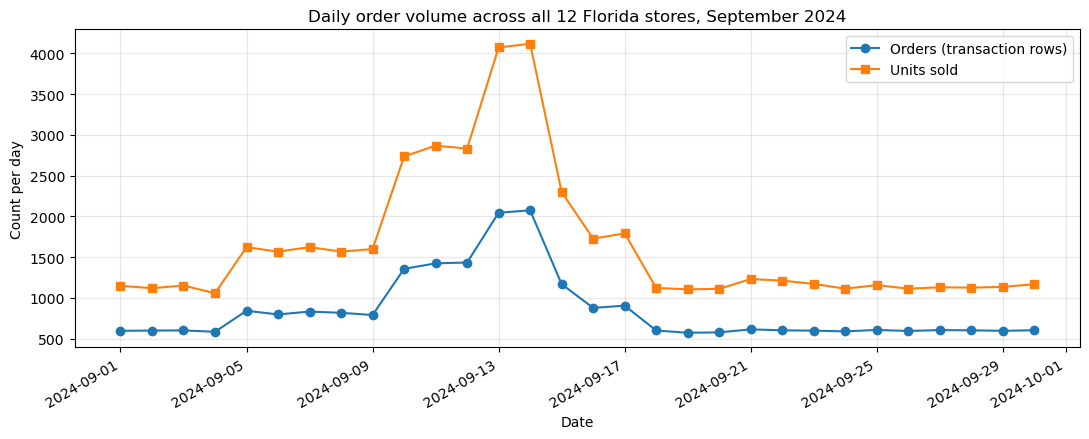

30 days plotted; 1 transactions left out (no date).


In [135]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily_orders['date'], daily_orders['orders'], marker='o', linewidth=1.5, label='Orders (transaction rows)')
ax.plot(daily_orders['date'], daily_orders['units'], marker='s', linewidth=1.5, label='Units sold')
ax.set_title('Daily order volume across all 12 Florida stores, September 2024')
ax.set_xlabel('Date')
ax.set_ylabel('Count per day')
ax.grid(alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
print(f'{len(daily_orders)} days plotted; {int(transactions["date_best"].isna().sum())} transactions left out (no date).')

## 12. Decision log and checkpoint numbers

In [136]:
decision_log = show_log()
decision_log

,file,step,decision,rows_affected
0,walmart,Whitespace,stripped leading/trailing spaces in text columns,2331
1,walmart,Duplicates,dropped exact duplicate rows,30
2,walmart,Store ID,standardized to 'FL-###',3607
3,walmart,Price,"removed '$' and spaces, converted unit_price t...",3026
4,walmart,Price,unit_price values that could not be parsed (le...,0
5,walmart,Negative qty,"policy 'abs': sign flipped, rows kept (assumed...",130
6,walmart,Category,mapped spelling variants to 10 canonical categ...,19358
7,walmart,SKU,added canonical_sku / canonical_product (raw s...,13988
8,walmart,Timestamp,parsed layout %Y-%m-%d %H:%M:%S e.g. 2024-09-...,12169
9,walmart,Timestamp,parsed layout %Y-%m-%dT%H:%M:%S e.g. 2024-09-...,2504


In [137]:
# The numbers the checkpoint self-check asks for
progress = {
    'rows_after_cleaning':  len(transactions),
    'decisions_logged':     len(decision_log),
    'canonical_products':   int(transactions['canonical_sku'].nunique()),
    'weather_api_rows':     len(weather),
    'weather_source':       weather['source'].iloc[0],
}
progress

{'rows_after_cleaning': 25532,
 'decisions_logged': 49,
 'canonical_products': 20,
 'weather_api_rows': 30,
 'weather_source': 'open-meteo'}

In [138]:
# Save clean tables so teammates can load them without re-running the pipeline (commit these, or add to .gitignore)
os.makedirs('clean', exist_ok=True)
for name, df in CLEAN.items():
    df.to_csv(f'clean/{name}_clean.csv', index=False)
weather.to_csv('clean/weather_daily.csv', index=False)
print('wrote', len(CLEAN) + 1, 'files to ./clean/')

wrote 7 files to ./clean/


---
# Analysis
Each question needs **code, at least one chart, and a written explanation**.

## Q1. Demand surge identification
**Owner:** TODO &nbsp; **Reviewer:** Ashley Huo

*What you need to decide first, and write down:* the **landfall date**, the **baseline window**, and the **surge window** (the 7 days before landfall). The data does not hand you these. Defend them with the daily chart above.
Then: units by category per window, percent increase, top 5, line chart of daily trend.

In [139]:
# TODO: the numbers
#Our baseline window are all the days in September before our surge, giving an accurate view of normal numbers for that time of year
landfall_date = pd.Timestamp('2024-09-26')
baseline_start = pd.Timestamp('2024-09-01')
baseline_end = pd.Timestamp ('2024-09-18')

#Our surge window is one week before the hurricane hit on the 26th
surge_start = pd.Timestamp('2024-09-19')
surge_end = pd.Timestamp('2024-09-25')

baseline = daily_orders[daily_orders['date'].between(baseline_start, baseline_end)]
surge = daily_orders[daily_orders['date'].between(surge_start, surge_end)]

baseline_avg = baseline['units'].mean()
surge_avg = surge['units'].mean()

multiple = surge_avg / baseline_avg

print(f'Hurricane Helene landfall: {landfall_date.date()}')
print(f'Baseline window: {baseline_start} to {baseline_end}')
print(f'Surge window: {surge_start} to {surge_end}')
print(f'Baseline average: {baseline_avg:.2f}')
print(f'Surge average: {surge_avg:.2f}')
print(f'Multiple: {multiple:.2f}')

Hurricane Helene landfall: 2024-09-26
Baseline window: 2024-09-01 00:00:00 to 2024-09-18 00:00:00
Surge window: 2024-09-19 00:00:00 to 2024-09-25 00:00:00
Baseline average: 2002.22
Surge average: 1158.14
Multiple: 0.58


In [140]:
# Create a complete daily series so dates with no transactions count as zero
daily_units = (
    transactions.dropna(subset=['date_best'])
    .groupby('date_best')['quantity_clean']
    .sum()
    .reindex(pd.date_range('2024-09-01', '2024-09-30'), fill_value=0)
    .rename_axis('date')
    .reset_index(name='units')
)

baseline = daily_units[
    daily_units['date'].between(baseline_start, baseline_end)
]

surge = daily_units[
    daily_units['date'].between(surge_start, surge_end)
]

baseline_avg = baseline['units'].mean()
surge_avg = surge['units'].mean()

surge_multiple = surge_avg / baseline_avg if baseline_avg else np.nan
percent_increase = (
    ((surge_avg - baseline_avg) / baseline_avg) * 100
    if baseline_avg else np.nan
)

print(f'\nBaseline average daily units: {baseline_avg:.2f}')
print(f'Surge average daily units: {surge_avg:.2f}')
print(f'Surge multiple: {surge_multiple:.2f}x')
print(f'Percentage increase: {percent_increase:.2f}%')


Baseline average daily units: 2002.22
Surge average daily units: 1158.14
Surge multiple: 0.58x
Percentage increase: -42.16%


In [141]:
# category-level daily avgs for both windows
dated_transactions = transactions.dropna(subset=['date_best']).copy()
baseline_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            baseline_start, baseline_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div(7)
)

# baseline contains 18 days, while the surge contains 7 days.
baseline_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            baseline_start, baseline_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div((baseline_end - baseline_start).days + 1)
)

surge_category = (
    dated_transactions[
        dated_transactions['date_best'].between(
            surge_start, surge_end
        )
    ]
    .groupby('category')['quantity_clean']
    .sum()
    .div((surge_end - surge_start).days + 1)
)

category_comparison = pd.concat(
    [
        baseline_category.rename('baseline_avg_daily_units'),
        surge_category.rename('surge_avg_daily_units')
    ],
    axis=1
).fillna(0)

category_comparison['unit_change'] = (
    category_comparison['surge_avg_daily_units']
    - category_comparison['baseline_avg_daily_units']
)

category_comparison['percent_increase'] = np.where(
    category_comparison['baseline_avg_daily_units'] > 0,
    category_comparison['unit_change']
    / category_comparison['baseline_avg_daily_units'] * 100,
    np.nan
)

category_comparison = category_comparison.sort_values(
    'surge_avg_daily_units', ascending=False
)

print('\nCategory comparison:')
display(category_comparison.round(2))


Category comparison:


,baseline_avg_daily_units,surge_avg_daily_units,unit_change,percent_increase
category,,,,
Emergency Supplies,715.78,379.14,-336.63,-47.03
Grocery,249.67,179.57,-70.10,-28.08
Game & Entertainment,172.89,105.86,-67.03,-38.77
Household,140.39,89.29,-51.10,-36.40
Baby Products,113.11,86.43,-26.68,-23.59
Electronics,127.39,75.14,-52.25,-41.01
Breakfast,239.39,74.43,-164.96,-68.91
Alcohol,101.61,63.14,-38.47,-37.86
Snacks,69.00,58.86,-10.14,-14.70


In [142]:
# Top five categories by average daily units during the surge
top_five_categories = category_comparison.head(5)

print('\nTop five categories during the surge:')
display(top_five_categories.round(2))


Top five categories during the surge:


,baseline_avg_daily_units,surge_avg_daily_units,unit_change,percent_increase
category,,,,
Emergency Supplies,715.78,379.14,-336.63,-47.03
Grocery,249.67,179.57,-70.10,-28.08
Game & Entertainment,172.89,105.86,-67.03,-38.77
Household,140.39,89.29,-51.10,-36.40
Baby Products,113.11,86.43,-26.68,-23.59


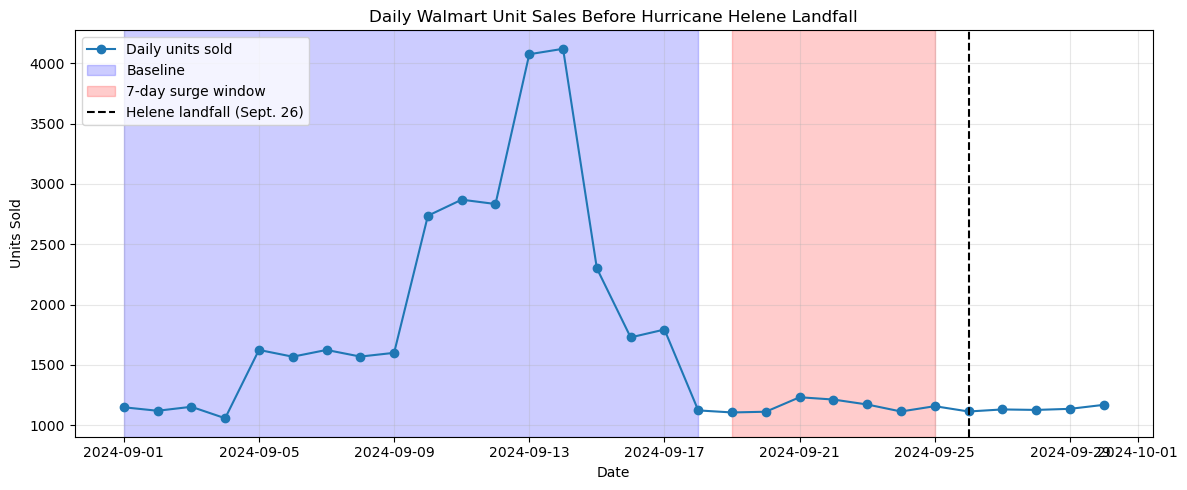

In [143]:
# TODO: the chart
# Daily sales trend chart
plt.figure(figsize=(12, 5))

plt.plot(
    daily_units['date'],
    daily_units['units'],
    marker='o',
    label='Daily units sold'
)

plt.axvspan(
    baseline_start, baseline_end,
    alpha=0.2, color='blue', label='Baseline'
)

plt.axvspan(
    surge_start, surge_end,
    alpha=0.2, color='red', label='7-day surge window'
)

plt.axvline(
    landfall_date,
    linestyle='--',
    color='black',
    label='Helene landfall (Sept. 26)'
)

plt.title('Daily Walmart Unit Sales Before Hurricane Helene Landfall')
plt.xlabel('Date')
plt.ylabel('Units Sold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

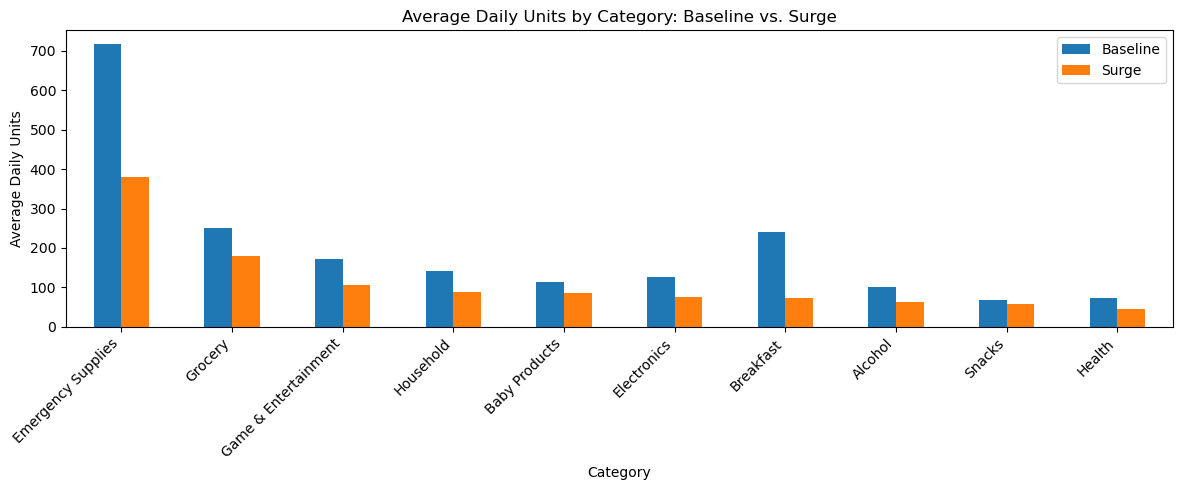

In [144]:
# Category comparison chart
category_comparison[
    ['baseline_avg_daily_units', 'surge_avg_daily_units']
].plot(kind='bar', figsize=(12, 5))

plt.title('Average Daily Units by Category: Baseline vs. Surge')
plt.xlabel('Category')
plt.ylabel('Average Daily Units')
plt.xticks(rotation=45, ha='right')
plt.legend(['Baseline', 'Surge'])
plt.tight_layout()
plt.show()

## Q2. The Pop-Tarts effect (SKU consolidation)
**Owner:** TODO &nbsp; **Reviewer:** Ashley Huo

Fragmented (raw `sku`) vs consolidated (`canonical_sku`) daily volume, side by side, plus a written paragraph on which business decisions differ between the two views.

In [145]:
# TODO Q2
#Counting distinct sku and distinct products
raw_skus = transactions['sku'].nunique()
canon_products = transactions['canonical_sku'].nunique()
#Determining how many SKU belong to each canonical product
family_size = products.groupby('canonical_product')['sku'].nunique().sort_values(ascending=False)

largest_fam = family_size.index[0]
largest_size = family_size.iloc[0]

print('Distinct raw:', raw_skus)
print('Canonical products:', canon_products)
print('Largest consolidated family:', largest_fam)
print('Family size:', largest_size)

#Making sure thatnothing changed in total units ater consolidation
before_units = transactions['quantity_clean'].sum()
after_units = (transactions.groupby('canonical_sku')['quantity_clean'].sum().sum())

print(f"Units before consolidation: {before_units}")
print(f"Units after consolidation:  {after_units}")
print(f"Totals were preserved? {before_units == after_units}")

Distinct raw: 45
Canonical products: 20
Largest consolidated family: Pop-Tarts Strawberry
Family size: 4
Units before consolidation: 49825
Units after consolidation:  49825
Totals were preserved? True


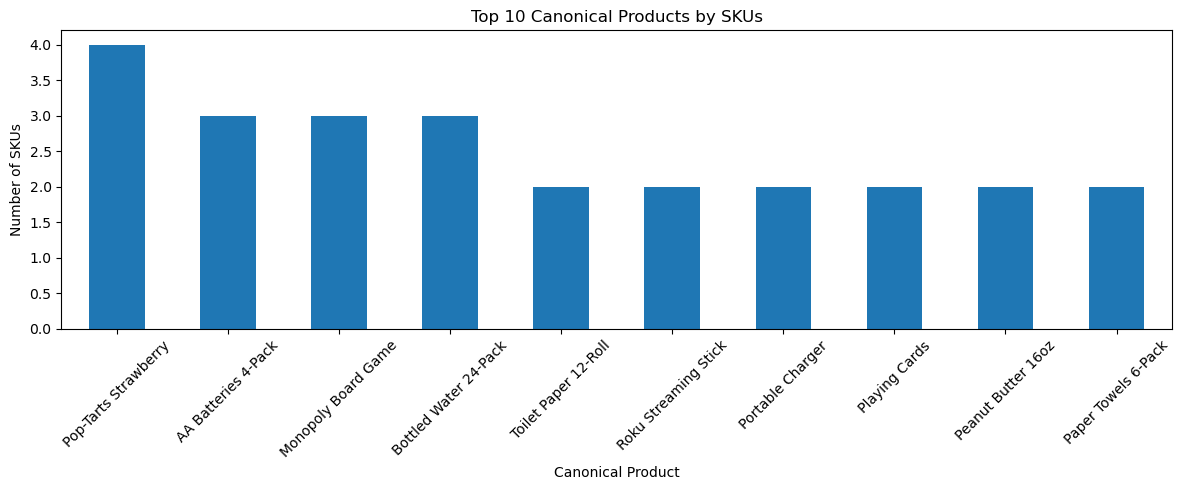

In [146]:
top_fams = family_size.head(10)

plt.figure(figsize=(12, 5))
top_fams.plot(kind='bar')
plt.title('Top 10 Canonical Products by SKUs')
plt.xlabel('Canonical Product')
plt.ylabel('Number of SKUs')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [147]:
orders_weather.head()

,date,orders,units,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,597,1149,6.4,18.7,open-meteo
1,2024-09-02,600,1120,22.0,12.7,open-meteo
2,2024-09-03,602,1153,32.7,20.6,open-meteo
3,2024-09-04,585,1058,21.2,12.6,open-meteo
4,2024-09-05,843,1624,20.8,15.2,open-meteo


Pop-Tarts raw SKU variants:


,transaction_count,total_units
sku,,
PT-12,538,1385
POPTART-STRAW,506,1306
PT_STRAWBERRY,515,1270
SKU#459812,503,1257


Fragmented total units: 5,218
Consolidated total units: 5,218
Totals preserved: True


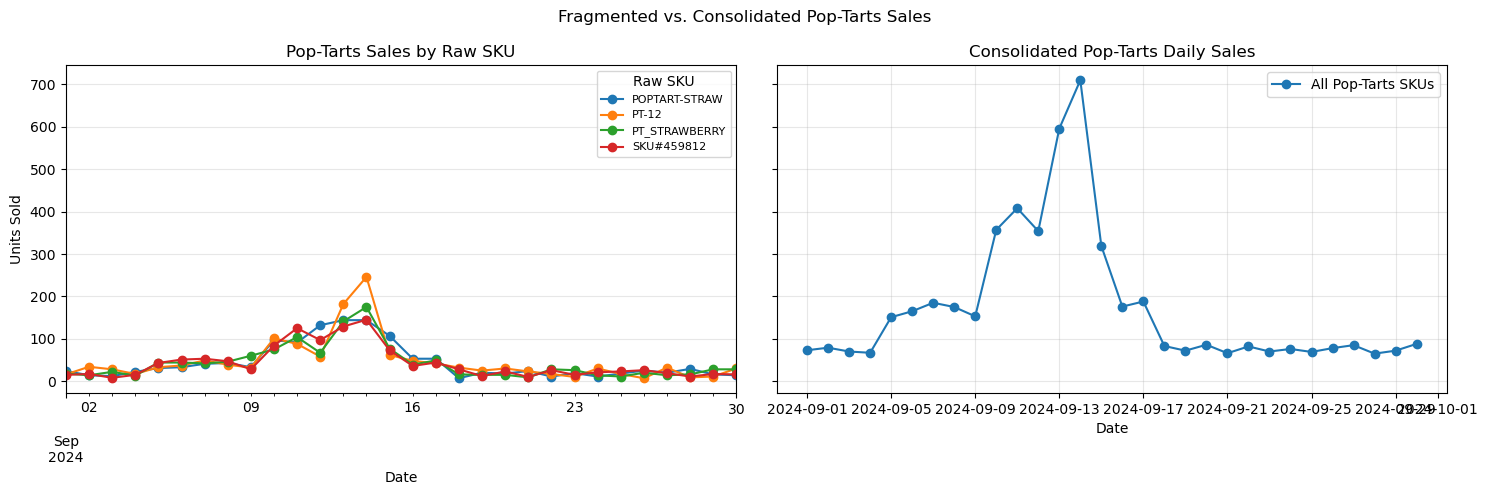

Largest individual SKU: PT-12
Units under that SKU: 1,385
Share of consolidated Pop-Tarts volume: 26.54%


In [ ]:
# Select all transactions belonging to the Pop-Tarts family
poptarts = transactions[
    transactions['canonical_sku'] == 'POPTART-STRAW'
].dropna(subset=['date_best']).copy()

print('Pop-Tarts raw SKU variants:')
display(
    poptarts.groupby('sku')['quantity_clean']
    .agg(['count', 'sum'])
    .rename(columns={
        'count': 'transaction_count',
        'sum': 'total_units'
    })
    .sort_values('total_units', ascending=False)
)

# Fragmented: daily units for each original SKU
fragmented_daily = (
    poptarts.groupby(['date_best', 'sku'])['quantity_clean']
    .sum()
    .unstack(fill_value=0)
)

# Consolidated: daily units across all Pop-Tarts SKUs
consolidated_daily = (
    poptarts.groupby('date_best')['quantity_clean']
    .sum()
    .rename('Pop-Tarts total')
)

# index both views to the full month
full_dates = pd.date_range('2024-09-01', '2024-09-30')

fragmented_daily = fragmented_daily.reindex(
    full_dates, fill_value=0
)

consolidated_daily = consolidated_daily.reindex(
    full_dates, fill_value=0
)

# Compare total units to verify consolidation preserves volume
fragmented_total = fragmented_daily.to_numpy().sum()
consolidated_total = consolidated_daily.sum()

print(f'Fragmented total units: {fragmented_total:,.0f}')
print(f'Consolidated total units: {consolidated_total:,.0f}')
print(
    'Totals preserved:',
    np.isclose(fragmented_total, consolidated_total)
)

# Side-by-side visualization
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

fragmented_daily.plot(
    kind='line',
    marker='o',
    ax=axes[0]
)

axes[0].set_title('Pop-Tarts Sales by Raw SKU')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Units Sold')
axes[0].legend(title='Raw SKU', fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(
    consolidated_daily.index,
    consolidated_daily.values,
    marker='o',
    label='All Pop-Tarts SKUs'
)

axes[1].set_title('Consolidated Pop-Tarts Daily Sales')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Units Sold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Fragmented vs. Consolidated Pop-Tarts Sales')
plt.tight_layout()
plt.show()

# Calculate consolidated volume for the largest raw SKU
raw_sku_totals = poptarts.groupby('sku')['quantity_clean'].sum()

largest_sku_units = raw_sku_totals.max()
largest_sku_share = (
    largest_sku_units / consolidated_total * 100
    if consolidated_total else np.nan
)

print(f'Largest individual SKU: {raw_sku_totals.idxmax()}')
print(f'Units under that SKU: {largest_sku_units:,.0f}')
print(f'Share of consolidated Pop-Tarts volume: {largest_sku_share:.2f}%')

In the fragmented view, a manager sees several separate SKU identifiers. Sales for the same product appear to be split across multiple rows or product entries. In the consolidated view, identifiers are grouped under one canonical product, showing the full daily demand for Pop-Tarts. For the business decision impact, fragmented reporting can understate demand for an individual product, making it harder to recognize a popular item, forecast demand, or make decisions to stock a certain product. Consolidation of the Pop-Tarts give an accurate product-level view of everything.

## Q3. Weather correlation
**Owner:** TODO &nbsp; **Reviewer:** TODO

Wind, precipitation, **pressure** vs daily sales by category; correlation chart; lag discussion. Start from `orders_weather`, `sales_weather` and the hourly starter in 9b.

In [149]:
# TODO Q3
#First I'm making sure the join worked
#Rows before merge
sales_before = len(daily_orders)

#Rows after merger
sales_after = len(orders_weather)

print(f'Rows before join: {sales_before}')
print(f'Rows after join:  {sales_after}')
print(f'Rows preserved? {sales_before== sales_after}')

#Where weather is coming from
weather_source = weather_daily['source'].iloc[0]
print(f'Weather source: {weather_source}')

#Seeing how many days will be analyzed in the correlation
n_days = len(orders_weather)

print(f'Days includes:{n_days}')

#Calculating correlations; dont have pressure input yet
corr_precip = orders_weather['units'].corr(orders_weather['precipitation_sum'])
corr_wind = orders_weather['units'].corr(orders_weather['windspeed_10m_max'])
#corr_pressure = orders_weather['units'].corr(orders_weather['pressure_msl'] )

print(f'Correlation with precipitation: {corr_precip:.3f}')
print(f'Correlation with wind: {corr_wind:.3f}')
#print(f'Correlation with pressure: {corr_pressure:.3f}')

#Finding the strongest correlations
correlations = {
    'Precipitation': corr_precip,
    'Wind': corr_wind,
    #'Pressure': corr_pressure#
}

strongest_var = max(correlations, key=lambda k: abs(correlations[k]))
strongest_corr = correlations[strongest_var]
print(f'Strongest relationship: {strongest_var} with 'f'a correlation of {strongest_corr:.3f}')


Rows before join: 30
Rows after join:  30
Rows preserved? True
Weather source: open-meteo
Days includes:30
Correlation with precipitation: 0.042
Correlation with wind: -0.279
Strongest relationship: Wind with a correlation of -0.279


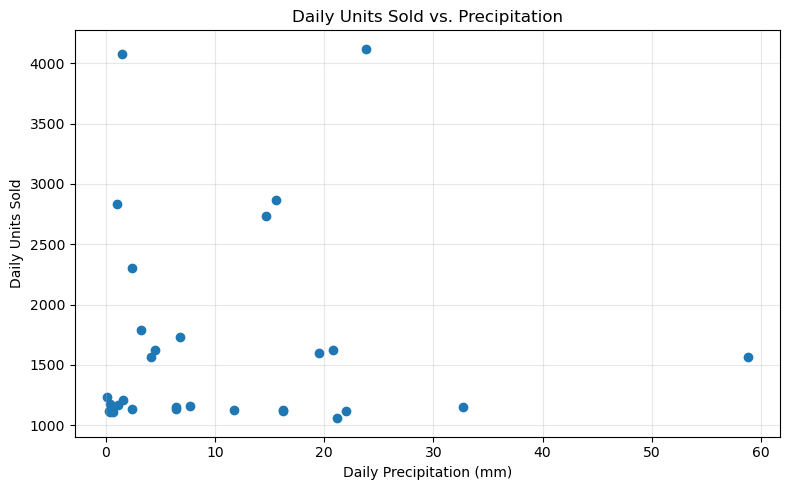

In [150]:
plt.figure(figsize =(8,5))
plt.scatter(orders_weather['precipitation_sum'],orders_weather['units'])

plt.title('Daily Units Sold vs. Precipitation')
plt.xlabel('Daily Precipitation (mm)')
plt.ylabel('Daily Units Sold')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Q4. Store-level geographic patterns
**Owner:** TODO &nbsp; **Reviewer:** TODO

Join `stores` (coordinates, region) to the transactions, compare surge timing and size per store, flag outliers.

In [151]:
# TODO Q4

## Q5. Signal vs artifact: the board games investigation
**Owner:** TODO &nbsp; **Reviewer:** TODO

Use `conn` (SQLite) with `pd.read_sql`. Cross-check the database against the transaction CSV, audit SKUs and categories, end with a recommendation.

In [152]:
# TODO Q5

## Reflection
Five questions from the brief, one solid paragraph each, every team member contributes.

1. Data quality impact: TODO
2. ETL trade-offs: TODO
3. Pipeline trust: TODO
4. Business vs data: TODO
5. Team collaboration: TODO